In [16]:
import csv
import random
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
import matplotlib.pyplot as plt

In [17]:
SEED = 42
BATCH = 32
EPOCHS = 5
LR = 1e-3
CLASSES = ["snow", "ice", "debris"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device =", device, "| torch =", torch.__version__)

device = cuda | torch = 2.11.0+cu128


In [18]:
rows = {"train": [], "val": [], "test": []}
with open("data_s2/patches.csv") as f:
    for r in csv.DictReader(f):
        rows[r["split"]].append((r["path"], int(r["label"])))
for k, v in rows.items():
    print(f"{k}: n={len(v)}")
assert rows["train"] and rows["val"] and rows["test"], "missing split — check data_s2/patches.csv"

train: n=389
val: n=186
test: n=265


In [19]:
pix = np.concatenate([
    (np.asarray(Image.open(p).convert("RGB")).astype("float32") / 255.0).reshape(-1, 3)
    for p, _ in rows["train"][:200]
])
MEAN = pix.mean(0).tolist()
STD = (pix.std(0) + 1e-6).tolist()
print("mean", [round(m, 4) for m in MEAN])
print("std", [round(s, 4) for s in STD])

mean [0.5691, 0.559, 0.5379]
std [0.3322, 0.3419, 0.3547]


In [20]:
class PatchSet(torch.utils.data.Dataset):
    def __init__(self, rows, mean, std, train=False):
        self.rows = rows
        self.mean = np.array(mean, dtype="float32")
        self.std = np.array(std, dtype="float32")
        self.train = train

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        path, label = self.rows[i]
        img = Image.open(path).convert("RGB")
        if self.train:
            if random.random() < 0.5:
                img = img.transpose(Image.FLIP_LEFT_RIGHT)
            img = img.rotate(random.uniform(-10, 10))
        a = np.asarray(img).astype("float32") / 255.0
        a = (a - self.mean) / self.std
        return torch.from_numpy(a.transpose(2, 0, 1).astype("float32")), int(label)

In [21]:
train_loader = torch.utils.data.DataLoader(PatchSet(rows["train"], MEAN, STD, train=True), batch_size=BATCH, shuffle=True)
val_loader = torch.utils.data.DataLoader(PatchSet(rows["val"], MEAN, STD), batch_size=BATCH)
test_loader = torch.utils.data.DataLoader(PatchSet(rows["test"], MEAN, STD), batch_size=BATCH)
xb, yb = next(iter(train_loader))
print("batch:", tuple(xb.shape), yb[:8].tolist())

batch: (32, 3, 64, 64) [2, 0, 2, 2, 2, 0, 0, 0]


In [22]:
class CNN(nn.Module):
    def __init__(self, hidden=128, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(64 * 4 * 4, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 3),
        )

    def forward(self, x):
        return self.head(self.features(x))

model = CNN().to(device)
print(f"params: {sum(p.numel() for p in model.parameters()):,}")

params: 150,979


In [23]:
model = CNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
counts = np.bincount([y for _, y in rows["train"]], minlength=3).astype("float32")
w = torch.tensor(counts.sum() / (3 * np.maximum(counts, 1))).to(device)
loss_fn = nn.CrossEntropyLoss(weight=w)
print("train counts:", {c: int(n) for c, n in zip(CLASSES, counts)}, "weight:", [round(float(x), 2) for x in w])

train counts: {'snow': 93, 'ice': 24, 'debris': 272} weight: [1.39, 5.4, 0.48]


In [24]:
def evaluate(loader):
    model.eval()
    y_pred, y_true = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            y_pred += model(xb).argmax(dim=1).cpu().tolist()
            y_true += yb.tolist()
    acc = 100.0 * sum(p == t for p, t in zip(y_pred, y_true)) / max(len(y_true), 1)
    return acc, y_pred, y_true

for epoch in range(EPOCHS):
    model.train()
    tot = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        tot += loss.item() * len(xb)
    train_loss = tot / len(rows["train"])
    val_acc, val_pred, val_true = evaluate(val_loader)
    val_f1 = f1_score(val_true, val_pred, average="macro", zero_division=0)
    print(f"epoch {epoch + 1}/{EPOCHS} loss={train_loss:.4f} val_acc={val_acc:.2f}% val_macro_f1={val_f1:.4f}")

epoch 1/5 loss=0.6399 val_acc=97.31% val_macro_f1=0.6615
epoch 2/5 loss=0.4393 val_acc=95.70% val_macro_f1=0.6516
epoch 3/5 loss=0.3376 val_acc=91.40% val_macro_f1=0.7266
epoch 4/5 loss=0.2139 val_acc=97.85% val_macro_f1=0.8225
epoch 5/5 loss=0.1336 val_acc=94.62% val_macro_f1=0.7446


In [25]:
print("train:", f"{evaluate(train_loader)[0]:.2f}%")
print("val:", f"{evaluate(val_loader)[0]:.2f}%")
print("test:", f"{evaluate(test_loader)[0]:.2f}%")

train: 96.14%
val: 94.62%
test: 94.72%


test acc: 94.72%
              precision    recall  f1-score   support

        snow     0.9636    0.9815    0.9725        54
         ice     0.8222    0.8810    0.8506        42
      debris     0.9758    0.9527    0.9641       169

    accuracy                         0.9472       265
   macro avg     0.9205    0.9384    0.9290       265
weighted avg     0.9490    0.9472    0.9478       265

saved outputs/s2_simple_confusion.png


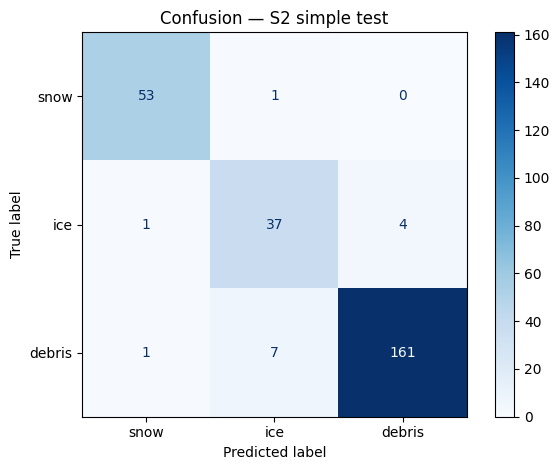

In [26]:
test_acc, y_pred, y_true = evaluate(test_loader)
print(f"test acc: {test_acc:.2f}%")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=[0, 1, 2], display_labels=CLASSES, cmap="Blues")
plt.title("Confusion — S2 simple test")
plt.tight_layout()
plt.savefig("outputs/s2_simple_confusion.png", dpi=120, bbox_inches="tight")
print("saved outputs/s2_simple_confusion.png")

In [27]:
Path("outputs").mkdir(exist_ok=True)
torch.save(model.state_dict(), "outputs/s2_simple.pt")
print("saved outputs/s2_simple.pt")

m2 = CNN().to(device)
m2.load_state_dict(torch.load("outputs/s2_simple.pt", map_location=device, weights_only=True))
model, _m = m2, model
acc2, _, _ = evaluate(test_loader)
print(f"reloaded test acc: {acc2:.2f}%")

saved outputs/s2_simple.pt
reloaded test acc: 94.72%


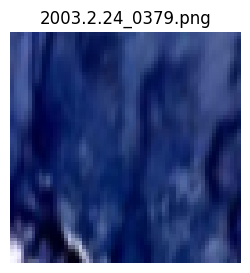

Prediction: debris
Confidence: 99.94%
  - snow: 0.00%
  - ice: 0.06%
  - debris: 99.94%


In [29]:
IMAGE_PATH = "data_s2/patches/test/debris/2003.2.24_0379.png"

import torch.nn.functional as F

img = Image.open(IMAGE_PATH).convert("RGB")
plt.figure(figsize=(3, 3))
plt.imshow(img)
plt.axis("off")
plt.title(IMAGE_PATH.split("/")[-1])
plt.show()

a = (np.asarray(img).astype("float32") / 255.0 - np.array(MEAN, dtype="float32")) / np.array(STD, dtype="float32")
t = torch.from_numpy(a.transpose(2, 0, 1).astype("float32")).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    probs = F.softmax(model(t)[0], dim=0).cpu().numpy()
pred = CLASSES[int(probs.argmax())]

print("=" * 50)
print(f"Prediction: {pred}")
print(f"Confidence: {probs.max() * 100:.2f}%")
for c, p in zip(CLASSES, probs):
    print(f"  - {c}: {p * 100:.2f}%")
print("=" * 50)